# Função 3 — `local.get_clearsky(times)` (refeito para estudo)

Baseado em `01_introducao.ipynb`, seção 3, Função 3.

**Objetivo:** calcular a irradiância de céu claro em Niterói e **conferir** o resultado com cálculos feitos à mão.

**Como usar:**
1. Escolha o kernel do `venv` do projeto (canto superior direito).
2. Rode as células de cima para baixo (Shift+Enter).
3. Onde aparecer `TODO(human)`, troque o `None` pelo seu código.

| Etapa | Quem escreve |
|---|---|
| 0 e 1 — imports, local, horários | pronto |
| 2 — `get_clearsky` | **você (TODO 1)** |
| 3 — conferência GHI | **você (TODO 2)** |
| 4 — energia do dia | **você (TODO 3)** |
| 5 — gráfico | pronto |

## Etapa 0 — Imports

In [11]:
import numpy as np
import pandas as pd
import pvlib
import matplotlib.pyplot as plt

## Etapa 1 — Local, horários e posição do Sol (pronta)

1. **Intuitivo:** antes de saber quanta luz chega, precisamos saber *onde* (Niterói), *quando* (26/10/2026, a cada 5 min) e *onde o Sol está no céu*.
2. **Técnico:** `Location` guarda latitude, longitude e fuso. `pd.date_range` cria um `DatetimeIndex` (lista de instantes com fuso). `get_solarposition` devolve ângulos como `apparent_zenith` (ângulo entre o Sol e a vertical, em graus).
3. **Aplicado:** igual às Funções 1 e 2 do curso. A posição do Sol será usada na Etapa 3.

In [12]:
local = pvlib.location.Location(
    latitude=-22.905,
    longitude=-43.122,
    tz="America/Sao_Paulo",
    name="Niteroi",
)

times = pd.date_range(
    start="2026-10-26 00:00", end="2026-10-26 23:55",
    freq="5min", tz=local.tz,
)

solar_position = local.get_solarposition(times)
solar_position[["apparent_zenith", "azimuth"]].head()

,apparent_zenith,azimuth
2026-10-26 00:00:00-03:00,144.217851,170.154142
2026-10-26 00:05:00-03:00,143.999502,168.105205
2026-10-26 00:10:00-03:00,143.741113,166.081493
2026-10-26 00:15:00-03:00,143.443534,164.086572
2026-10-26 00:20:00-03:00,143.107715,162.123649


## Etapa 2 — Irradiância de céu claro (TODO 1)

1. **Intuitivo:** "se o céu estivesse perfeitamente limpo, quanta irradiância chegaria a cada 5 minutos?"
2. **Técnico:** assinatura (pvlib 0.15.2): `get_clearsky(times, model='ineichen', ...)`. O modelo **Ineichen-Perez** usa a altitude e a **turbidez de Linke** (o quanto a atmosfera está "suja" de poeira e vapor d'água, tirada de uma tabela mensal). Devolve um `DataFrame` com `ghi`, `dni`, `dhi` em W/m².
3. **Aplicado:** é a **referência do dia ideal**. Comparando com o `Pac` medido dos inversores ABB, dá para separar dias claros de nublados.

**Sua tarefa:** chame o método `get_clearsky` do objeto `local`, passando `times` e escolhendo explicitamente o modelo `"ineichen"`.

**Resultado esperado:** tabela com colunas `ghi`, `dni`, `dhi`; as primeiras linhas (madrugada) em `0.0`.

💡 Se precisar, rode `help(local.get_clearsky)` numa célula nova.

In [13]:
clearsky = local.get_clearsky(times, model="ineichen", solar_position=solar_position)

clearsky.head()

,ghi,dni,dhi
2026-10-26 00:00:00-03:00,0.0,0.0,0.0
2026-10-26 00:05:00-03:00,0.0,0.0,0.0
2026-10-26 00:10:00-03:00,0.0,0.0,0.0
2026-10-26 00:15:00-03:00,0.0,0.0,0.0
2026-10-26 00:20:00-03:00,0.0,0.0,0.0


## Etapa 3 — Conferência: GHI = DNI·cos(θz) + DHI (TODO 2)

1. **Intuitivo:** a luz no chão (GHI) é a soma da luz que vem direto do Sol ("deitada" pelo ângulo) com a luz espalhada pelo céu.
2. **Técnico:** **GHI = DNI · cos(θz) + DHI**, onde θz é o ângulo zenital. A DNI é medida perpendicular ao Sol, por isso precisa do cosseno para ser projetada no plano horizontal.
3. **Aplicado:** é o mesmo teste de qualidade usado com dados medidos (A1_WeatherData): se a soma não fecha, algum sensor está errado.

**Sua tarefa:** calcule `ghi_calculado` usando as colunas de `clearsky` e a coluna `"apparent_zenith"` de `solar_position`.

⚠️ `np.cos()` espera ângulo em **radianos**; o zênite vem em **graus**.

**Resultado esperado:** diferença praticamente zero (algo como `1e-16`).

In [14]:
# TODO(human): calcule o GHI a partir de DNI, DHI e do zênite
ghi_calculado = clearsky["dni"] * np.cos(np.radians(solar_position["apparent_zenith"])) + clearsky["dhi"]

diferenca_max = (clearsky["ghi"] - ghi_calculado).abs().max()
print(f"Maior diferença entre GHI do modelo e GHI calculado: {diferenca_max:.6f} W/m²")

Maior diferença entre GHI do modelo e GHI calculado: 0.000000 W/m²


## Etapa 4 — Energia do dia e pico (TODO 3)

1. **Intuitivo:** irradiância (W/m²) é *potência*. Para ter *energia* (kWh/m²), somamos potência × tempo.
2. **Técnico:** integral numérica por soma de retângulos: Σ(GHI) × Δt, com Δt em **horas**; depois ÷ 1000 para passar de Wh para kWh.
3. **Aplicado:** esse número é o **HSP (horas de sol pleno)** do dia. É a mesma lógica de calcular energia a partir do `Pac` de 1 minuto.

**Sua tarefa:** calcule `irradiacao_dia_kwh`. Cada ponto de `clearsky["ghi"]` vale por 5 minutos. Pense: 5 min são quantas horas?

**Resultado esperado:** em torno de **7,9 kWh/m²**; pico ≈ **1040 W/m² às 11:35**.

In [ ]:
# TODO(human): calcule a irradiação diária em kWh/m²
irradiacao_dia_kwh = clearsky["ghi"].sum() * (5/60)/1000  # ×(5/60): 5 min em horas → Wh/m² | ÷1000: Wh → kWh/m²

pico_w = clearsky["ghi"].max()
hora_pico = clearsky["ghi"].idxmax()

print(f"Irradiação diária (GHI): {irradiacao_dia_kwh:.2f} kWh/m²")
print(f"Pico de GHI: {pico_w:.0f} W/m² às {hora_pico:%H:%M}")

Irradiação diária (GHI): 7.90 kWh/m²
Pico de GHI: 1040 W/m² às 11:35


## Etapa 5 — Gráfico (pronto)

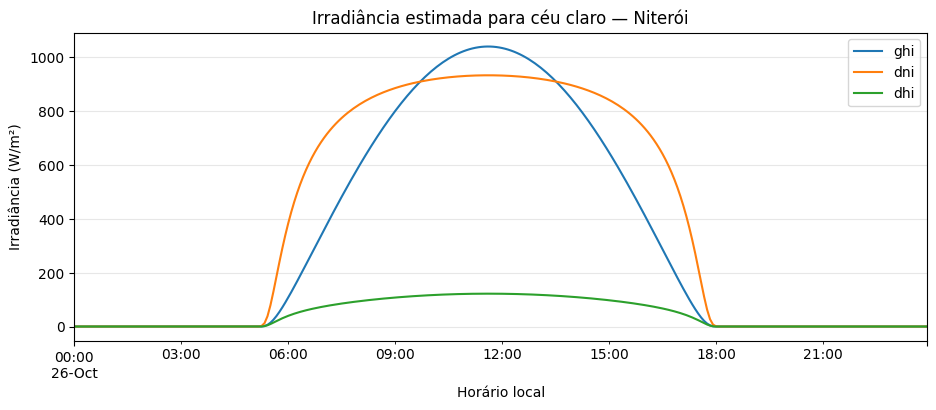

In [16]:
ax = clearsky[["ghi", "dni", "dhi"]].plot(figsize=(11, 4))
ax.set(title="Irradiância estimada para céu claro — Niterói",
       xlabel="Horário local", ylabel="Irradiância (W/m²)")
ax.grid(alpha=0.3)
plt.show()

## Para pensar

Por que a madrugada aparece com `0.0` e não com `NaN`?

Minha resposta: Porque como estou usando dados numéricos da irradiância ele está medindo que chega uma quantidade zero de irradiância.